In [1]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END


class State(TypedDict):
    question: str
    answer: str
    llm_answer: str

In [2]:
def greet(state: State):
    return {"answer": "You asked: " + state["question"]}

In [3]:
import os
from dataclasses import dataclass
from langchain_ollama import ChatOllama


@dataclass
class LLMConfig:
    model: str = os.getenv("OLLAMA_MODEL", "qwen3:0.6b")        # run `ollama pull <model>` first
    base_url: str = os.getenv("OLLAMA_HOST", "http://localhost:11434")
    temperature: float = 0.2
    num_ctx: int = 4096        # context window
    num_predict: int = 256     # max tokens to generate
    timeout: float = 120       # seconds (client timeout)


def build_llm(cfg: LLMConfig) -> ChatOllama:
    return ChatOllama(
        model=cfg.model,
        base_url=cfg.base_url,
        temperature=cfg.temperature,
        num_ctx=cfg.num_ctx,
        num_predict=cfg.num_predict,
        client_kwargs={"timeout": cfg.timeout},
    )


llm_config = LLMConfig()
llm = build_llm(llm_config)


def call_llm(state: State):
    response = llm.invoke(state["question"])
    return {"llm_answer": response.content}

In [4]:
builder = StateGraph(State)
builder.add_node("greet", greet)
builder.add_node("call_llm", call_llm)

builder.add_edge(START, "greet")
builder.add_edge("greet", "call_llm")
builder.add_edge("call_llm", END)

In [5]:
graph = builder.compile()

myState = {
    "question": "What is a sun?",
    "answer": "",
    "llm_answer": "",
}

result = graph.invoke(myState)
print(result)

{'question': 'What is a sun?', 'answer': 'You asked: What is a sun?', 'llm_answer': "A sun is a celestial body in our solar system, a massive, luminous sphere of gas and dust that emits intense light and heat. It plays a crucial role in our planet's climate, weather patterns, and life. Here's a simple explanation:\n\n- **Definition**: A sun is a planet, specifically the Sun, which is the central star in our solar system."}


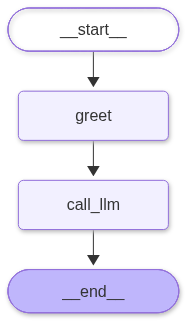

In [6]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))